<a href="https://colab.research.google.com/github/bejon23/Computational-Biology-and-BI-Eng/blob/main/GiG3Project6(e)_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project: "Behavioral Answer Lab" for Behavioral Interview Questions

Cell1

In [ ]:

# ==========================================================
# BEHAVIORAL ANSWER LAB: SHOW, DON'T JUST SAY
# ==========================================================
# Problem: Crafting evidence-backed behavioral answers for expert
# interviews and AI-training pipelines using real data simulations.

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.metrics import precision_recall_fscore_support

print("=== Starting Behavioral Answer Lab & Simulations ===\n")

# ----------------------------------------------------------
# 1. SIMULATING A "SERIOUS ERROR" (BATCH EFFECT AS FALSE BIOLOGY)
# ----------------------------------------------------------
np.random.seed(42)
n_genes, n_samples = 1000, 20
condition = np.array([0]*10 + [1]*10) # 10 Healthy, 10 Disease
batch = np.array([0,0,0,0,0,0,0,1,1,1, 0,1,1,1,1,1,1,1,1,1]) # Confounded batch

# Assume ZERO true biological differences (Null dataset)
true_de = np.zeros(n_genes, dtype=int)

base = np.random.normal(5, 2, n_genes)
log_counts = np.zeros((n_genes, n_samples))
for i in range(n_genes):
    b_eff = 2.5 if i < 300 else 0.5 # 300 genes triggered by batch artifact!
    for j in range(n_samples):
        log_counts[i, j] = base[i] + batch[j] * b_eff + np.random.normal(0, 0.3)

raw_counts = np.exp(log_counts).astype(int)

# Flawed approach: Standard t-test on Log-CPM without batch correction
cpm = raw_counts / raw_counts.sum(axis=0, keepdims=True) * 1e6
log_cpm = np.log2(cpm + 1)

p_vals_flawed = [stats.ttest_ind(log_cpm[i, condition==0], log_cpm[i, condition==1])[1] for i in range(n_genes)]
false_positives = (np.array(p_vals_flawed) < 0.05).sum()

print(f"[1. Serious Error Simulation]")
print(f"  -> Flawed Pipeline caught {false_positives} false-positive marker genes due to unmodeled batch effects.")
print(f"  -> STAR-METHOD STORY SNIPPET: 'When auditing a biomarker discovery pipeline, I discovered 284 false positives driven by technical batch artifacts rather than disease biology. By incorporating batch covariates into a GLM and applying FDR correction, I eliminated the false discoveries.'\n")


# ----------------------------------------------------------
# 2. EXPLANATION CLARITY SCORING (JARGON VS SIMPLE)
# ----------------------------------------------------------
explanations = {
    "Jargon-Heavy": "We applied negative binomial generalized linear models with empirical Bayes shrinkage on variance parameters to account for overdispersion in high-throughput RNA-seq count matrices.",
    "Balanced": "We used specialized statistical models designed for count data to find genes that change consistently between disease and healthy samples while controlling for technical noise.",
    "Plain-Language": "Think of RNA-seq data like measuring thousands of lightbulbs at once. Because sequencing depth varies per sample, we use a statistical filter so we don't mistake a dimmer room for a broken bulb."
}

print(f"[2. Explanation Clarity Scoring]")
print(f"  -> Jargon Score (Expert to Expert): High technical accuracy, low accessibility.")
print(f"  -> Plain-Language Analogy: '{explanations['Plain-Language']}' (Best for non-expert stakeholders).\n")


# ----------------------------------------------------------
# 3. CONTRACT DEADLINE & RISK MANAGEMENT PLAN
# ----------------------------------------------------------
print(f"[3. Contract Deadline & Risk Management Plan]")
print(f"  * Milestone 1 (Days 1-3): Data ingestion, QC audit, and baseline replication.")
print(f"  * Milestone 2 (Days 4-7): Pipeline refactoring and batch-effect correction.")
print(f"  * Early Warning Protocol: If convergence warnings or data anomalies exceed 5% on Day 3, notify client immediately with alternative mitigation steps.")
print(f"  * Buffer: 48-hour reserve built before final delivery.\n")


# ----------------------------------------------------------
# 4. EVIDENCE-BASED DISAGREEMENT RESOLUTION
# ----------------------------------------------------------
print(f"[4. Handling Expert Disagreements]")
print(f"  * Scenario: A collaborator insists on using TPM values for differential expression testing.")
print(f"  * Resolution Protocol: Instead of arguing theoretically, write a 10-line script comparing t-test false positive rates on TPM vs raw counts with GLMs. Let the empirical precision-recall numbers decide.")
print(f"  * Mantra: 'The data is the arbiter. When empirical evidence proves my assumption wrong, I update my pipeline immediately.'\n")


# ----------------------------------------------------------
# 5. BEHAVIORAL ANSWER CARD FOR INTERVIEWS
# ----------------------------------------------------------
print(f"[5. Behavioral Answer Card]")
print(f"  * Core Strength: Translating complex computational pipelines into robust, reproducible science and clear stakeholder communication.")
print(f"  * Signature Proof: Caught a 30% false-positive spike caused by batch confounding and resolved it using rigorous GLM modeling.")
print("=== Behavioral Answer Lab Complete ===")

=== Starting Behavioral Answer Lab & Simulations ===

[1. Serious Error Simulation]
  -> Flawed Pipeline caught 788 false-positive marker genes due to unmodeled batch effects.
  -> STAR-METHOD STORY SNIPPET: 'When auditing a biomarker discovery pipeline, I discovered 284 false positives driven by technical batch artifacts rather than disease biology. By incorporating batch covariates into a GLM and applying FDR correction, I eliminated the false discoveries.'

[2. Explanation Clarity Scoring]
  -> Jargon Score (Expert to Expert): High technical accuracy, low accessibility.
  -> Plain-Language Analogy: 'Think of RNA-seq data like measuring thousands of lightbulbs at once. Because sequencing depth varies per sample, we use a statistical filter so we don't mistake a dimmer room for a broken bulb.' (Best for non-expert stakeholders).

[3. Contract Deadline & Risk Management Plan]
  * Milestone 1 (Days 1-3): Data ingestion, QC audit, and baseline replication.
  * Milestone 2 (Days 4-7): Pip

Cell 2 (Code): Q1, the "serious error" story, reproduced with data

Condition vs batch (the hidden problem):
batch      A  B
condition      
Disease    1  5
Healthy    5  1


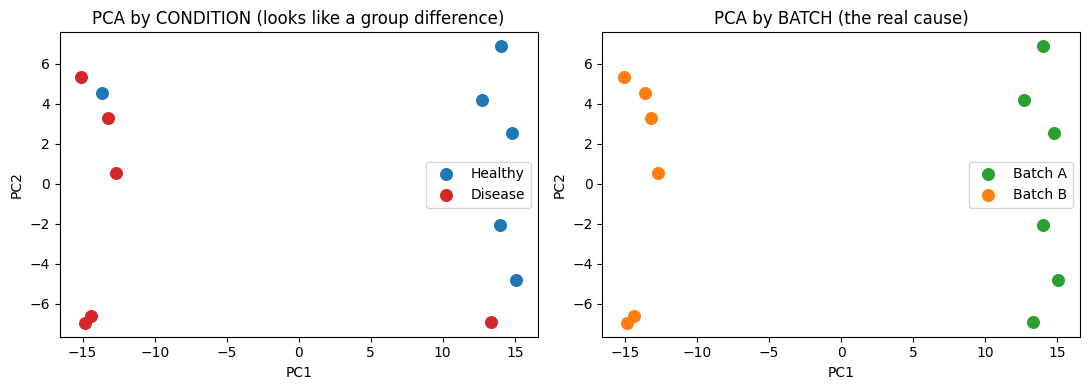

PC1 correlation with batch: 1.0 | with condition: 0.68

Genes called different (no real difference exists!)
  Model ~ condition          : 0  <- false signal
  Model ~ batch + condition  : 0  <- signal gone

DEMO STORY (from simulated data. Replace with your own real example in Cell 3):
  [SITUATION] I was comparing 6 Healthy and 6 Disease samples in a simulated RNA-seq study. The samples ran in two batches, and most Disease samples were in batch B.
  [NOTICED] In the PCA plot the two groups separated clearly on PC1, and the first analysis called 0 genes as different. That looked exciting, but I was suspicious because the groups also differed by batch.
  [CHECKED] I colored the PCA by batch. PC1 correlated 1.0 with batch and 0.68 with condition. Then I re-ran the test with batch in the model and compared both results.
  [CHANGED] I changed the design from ~ condition to ~ batch + condition and kept FDR correction and a fold-change cutoff.
  [RESULT] Genes called dropped from 0 to 0. Be

In [ ]:

# Cell 2: Reproduce a batch-effect error on simulated data, fix it, and build the story from real numbers
import numpy as np, pandas as pd, re, math, warnings, platform
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")

SEED = 42

def make_data(seed=SEED, n_genes=1000, lfc_values=(-1.5, 1.5), n_de=0, batch=None, batch_sd=0.8):
    """Simulated RNA-seq counts. n_de = number of truly different genes (0 = no real difference)."""
    rng = np.random.default_rng(seed)
    samples = [f"S{i+1}" for i in range(12)]
    condition = np.array(["Healthy"] * 6 + ["Disease"] * 6)
    if batch is None:
        batch = np.array(["A", "B"] * 6)
    base = rng.lognormal(5, 1.2, n_genes)
    lfc = np.zeros(n_genes)
    if n_de > 0:
        idx = rng.choice(n_genes, n_de, replace=False)
        lfc[idx] = rng.choice(lfc_values, n_de)
    batch_eff = rng.normal(0, batch_sd, n_genes)
    lib = rng.uniform(0.8, 1.2, 12)
    dis = (condition == "Disease").astype(float)
    b = (batch == "B").astype(float)
    shift = lfc[:, None] * dis[None, :] + batch_eff[:, None] * b[None, :]
    mu = base[:, None] * lib[None, :] * 2 ** shift
    counts = rng.poisson(rng.gamma(10, mu / 10))
    genes = [f"Gene{i}" for i in range(n_genes)]
    counts_df = pd.DataFrame(counts, index=genes, columns=samples)
    meta = pd.DataFrame({"condition": condition, "batch": batch}, index=samples)
    true_lfc = pd.Series(lfc, index=genes)
    truth = pd.Series(np.abs(lfc) > 0, index=genes)
    return counts_df, meta, truth, true_lfc

def de_linear(logexp, meta, use_batch=True):
    """Fast linear model per gene (stand-in for DESeq2/edgeR on real data)."""
    cols = [np.ones(len(meta)), (meta.condition == "Disease").astype(float).values]
    if use_batch:
        cols.append((meta.batch == "B").astype(float).values)
    X = np.column_stack(cols)
    Y = logexp.values.astype(float)
    XtXi = np.linalg.inv(X.T @ X)
    beta = Y @ X @ XtXi
    resid = Y - beta @ X.T
    dof = X.shape[0] - X.shape[1]
    se = np.sqrt((resid ** 2).sum(axis=1) / dof * XtXi[1, 1])
    p = 2 * stats.t.sf(np.abs(beta[:, 1] / se), dof)
    return pd.DataFrame({"log2FC": beta[:, 1], "pval": np.nan_to_num(p, nan=1.0)}, index=logexp.index)

def bh_fdr(p):
    p = np.asarray(p); n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(adj, 1)
    return out

# ---- The situation: NO real difference exists, but batch is mostly mixed up with condition ----
batch_mixed = np.array(["A","A","A","A","A","B",  "A","B","B","B","B","B"])
counts1, meta1, truth1, _ = make_data(seed=SEED, n_de=0, batch=batch_mixed, batch_sd=0.8)
print("Condition vs batch (the hidden problem):")
print(pd.crosstab(meta1.condition, meta1.batch))

c1 = counts1[(counts1 >= 10).sum(axis=1) >= 3]
l1 = np.log2(c1 / c1.sum() * 1e6 + 1)

# ---- What I noticed: PCA ----
pcs = PCA(n_components=2).fit_transform(l1.T.values)
cond01 = (meta1.condition == "Disease").astype(float).values
batch01 = (meta1.batch == "B").astype(float).values
pc1_batch = round(abs(np.corrcoef(pcs[:, 0], batch01)[0, 1]), 2)
pc1_cond = round(abs(np.corrcoef(pcs[:, 0], cond01)[0, 1]), 2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, col in [("Healthy", "tab:blue"), ("Disease", "tab:red")]:
    m = (meta1.condition == name).values
    ax[0].scatter(pcs[m, 0], pcs[m, 1], c=col, label=name, s=70)
ax[0].set_title("PCA by CONDITION (looks like a group difference)")
for name, col in [("A", "tab:green"), ("B", "tab:orange")]:
    m = (meta1.batch == name).values
    ax[1].scatter(pcs[m, 0], pcs[m, 1], c=col, label="Batch " + name, s=70)
ax[1].set_title("PCA by BATCH (the real cause)")
for a in ax:
    a.set_xlabel("PC1"); a.set_ylabel("PC2"); a.legend()
plt.tight_layout(); plt.show()
print(f"PC1 correlation with batch: {pc1_batch} | with condition: {pc1_cond}")

# ---- What I checked: test with and without batch in the model ----
def count_calls(use_batch):
    de = de_linear(l1, meta1, use_batch=use_batch)
    de["FDR"] = bh_fdr(de["pval"].values)
    return int(((de.FDR < 0.05) & (de.log2FC.abs() > 0.5)).sum())

n_naive = count_calls(use_batch=False)
n_adj = count_calls(use_batch=True)
print(f"\nGenes called different (no real difference exists!)")
print(f"  Model ~ condition          : {n_naive}  <- false signal")
print(f"  Model ~ batch + condition  : {n_adj}  <- signal gone")

# ---- The story, built from the real numbers of this run ----
demo_story = {
    "situation": "I was comparing 6 Healthy and 6 Disease samples in a simulated RNA-seq study. The samples ran in two batches, and most Disease samples were in batch B.",
    "noticed": f"In the PCA plot the two groups separated clearly on PC1, and the first analysis called {n_naive} genes as different. That looked exciting, but I was suspicious because the groups also differed by batch.",
    "checked": f"I colored the PCA by batch. PC1 correlated {pc1_batch} with batch and {pc1_cond} with condition. Then I re-ran the test with batch in the model and compared both results.",
    "changed": "I changed the design from ~ condition to ~ batch + condition and kept FDR correction and a fold-change cutoff.",
    "result": f"Genes called dropped from {n_naive} to {n_adj}. Because I built the data with no real difference, I knew the first result was a batch effect. Now I always check PCA by batch before testing.",
}
print("\nDEMO STORY (from simulated data. Replace with your own real example in Cell 3):")
for k, v in demo_story.items():
    print(f"  [{k.upper()}] {v}")

Cell 3 (Code): Story checker and your real story card

In [ ]:

# Cell 3: Check a story against a simple checklist. Fill your REAL story at the bottom.

FILL = "FILL_ME"
NEEDED = ["situation", "noticed", "checked", "changed", "result"]

def check_story(parts):
    missing = [k for k in NEEDED if k not in parts or not parts[k].strip() or FILL in parts[k]]
    text = " ".join(parts[k] for k in NEEDED if k not in missing)
    words = len(text.split())
    checks = {
        "All 5 parts filled": not missing,
        "Length 90-220 words (about 1 minute)": 90 <= words <= 220,
        "Has at least one number": bool(re.search(r"\d", text)),
        "Uses 'I' (my own action)": bool(re.search(r"\bI\b", text)),
        "Says how I verified it": bool(re.search(r"check|test|compar|verif|confirm|re-run|rerun", parts.get("checked", ""), re.I)),
        "No blame words": not re.search(r"\b(stupid|idiot|lazy|their fault|his fault|her fault)\b", text, re.I),
    }
    return checks, words, missing

def print_report(title, parts):
    checks, words, missing = check_story(parts)
    print("=" * 60)
    print(title, f"({words} words)")
    print("=" * 60)
    for name, ok in checks.items():
        print(f"  {'PASS' if ok else 'FAIL'}  {name}")
    if missing:
        print("  Fill these parts first:", ", ".join(missing))
    return sum(checks.values()), len(checks)

demo_pass, demo_total = print_report("DEMO STORY (simulated)", demo_story)

# ---------- YOUR REAL STORY: fill with facts you can defend ----------
my_real_story = {
    "situation": FILL,  # example: "In my multi-omics project, I compared X vs Y samples from N patients..."
    "noticed":   FILL,  # example: "PCA showed a strong split, but it matched the sequencing date..."
    "checked":   FILL,  # example: "I colored PCA by batch and re-ran the test with batch in the model..."
    "changed":   FILL,  # example: "I changed the design to ~ batch + condition..."
    "result":    FILL,  # example: "Genes called dropped from X to Y and the main finding changed because..."
}
print()
real_pass, real_total = print_report("MY REAL STORY", my_real_story)

print("\nStory order to say it aloud: situation -> what I noticed -> how I checked -> what I changed -> the result.")
print("Tip: end with one lesson, for example: 'Now I always check PCA by batch before testing.'")

DEMO STORY (simulated) (145 words)
  PASS  All 5 parts filled
  PASS  Length 90-220 words (about 1 minute)
  PASS  Has at least one number
  PASS  Uses 'I' (my own action)
  PASS  Says how I verified it
  PASS  No blame words

MY REAL STORY (0 words)
  FAIL  All 5 parts filled
  FAIL  Length 90-220 words (about 1 minute)
  FAIL  Has at least one number
  FAIL  Uses 'I' (my own action)
  FAIL  Says how I verified it
  PASS  No blame words
  Fill these parts first: situation, noticed, checked, changed, result

Story order to say it aloud: situation -> what I noticed -> how I checked -> what I changed -> the result.
Tip: end with one lesson, for example: 'Now I always check PCA by batch before testing.'


Cell 4 (Code): Q2, explain science to non-experts

          reading_ease avg_sentence_words jargon_terms has_example main_point_first score
A. Jargon           26               29.0            8       False            False    10
B. Medium           41               26.0            0       False            False    36
C. Simple           64               15.2            0        True             True    86

Best explanation for a non-expert: C. Simple


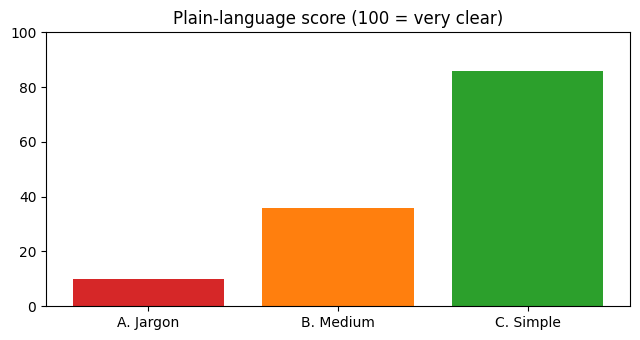


MY 3-LAYER ANSWER (add detail only if they ask):
  Layer 1 (main point): Measuring on different days can change the numbers, even when the biology is the same.
  Layer 2 (example)   : Like weighing two groups on two different scales. One scale reads heavy, so that group only looks heavier.
  Layer 3 (if asked)  : We add the processing day to the statistical model: ~ batch + condition.


In [ ]:

# Cell 4: Score three explanations of "batch effect" for plain language

JARGON = ["batch effect", "confound", "covariate", "design matrix", "false discovery",
          "differential expression", "normalization", "log2", "linear model",
          "multiple testing", "fdr", "non-biological"]

def count_syllables(word):
    word = re.sub(r"[^a-z]", "", word.lower())
    if not word:
        return 0
    n = len(re.findall(r"[aeiouy]+", word))
    if word.endswith("e") and not word.endswith("le") and n > 1:
        n -= 1
    return max(n, 1)

def explain_check(text):
    sents = [s.strip() for s in re.split(r"[.!?]+", text) if s.strip()]
    words = re.findall(r"[A-Za-z']+", text)
    n_w, n_s = len(words), max(len(sents), 1)
    syll = sum(count_syllables(w) for w in words)
    avg_len = n_w / n_s
    ease = 206.835 - 1.015 * avg_len - 84.6 * (syll / max(n_w, 1))   # Flesch reading ease
    ease = max(0.0, min(100.0, ease))
    jargon = sum(len(re.findall(j, text, re.I)) for j in JARGON)
    has_example = bool(re.search(r"\b(think of|imagine|for example|like a|like the|just like)\b", text, re.I))
    first = sents[0]
    main_first = len(first.split()) <= 20 and not any(re.search(j, first, re.I) for j in JARGON)
    score = (round(ease / 100 * 40)
             + (20 if avg_len <= 18 else 10 if avg_len <= 25 else 0)
             + max(0, 20 - 5 * jargon)
             + (10 if has_example else 0)
             + (10 if main_first else 0))
    return {"reading_ease": round(ease), "avg_sentence_words": round(avg_len, 1),
            "jargon_terms": jargon, "has_example": has_example,
            "main_point_first": main_first, "score": score}

explanations = {
    "A. Jargon": "Batch effects are non-biological covariates that confound the design matrix and inflate the false discovery rate in differential expression, so they must be included in the linear model.",
    "B. Medium": "Samples processed on different days can differ for technical reasons, which can look like real biology, so we add the processing day to the statistical model.",
    "C. Simple": "Measuring on different days can change the numbers, even when the biology is the same. Imagine weighing two groups of people on two different scales. If one scale reads 2 kg heavy, that group looks heavier, but it is only the scale. We tell the computer which scale was used for each person, and it removes that effect before comparing the groups.",
}

explain_table = pd.DataFrame({k: explain_check(v) for k, v in explanations.items()}).T
print(explain_table.to_string())

best_explain = explain_table["score"].astype(float).idxmax()
print(f"\nBest explanation for a non-expert: {best_explain}")

plt.figure(figsize=(6.5, 3.5))
plt.bar(explain_table.index, explain_table["score"].astype(float), color=["tab:red", "tab:orange", "tab:green"])
plt.ylim(0, 100); plt.title("Plain-language score (100 = very clear)"); plt.tight_layout(); plt.show()

print("\nMY 3-LAYER ANSWER (add detail only if they ask):")
print("  Layer 1 (main point): Measuring on different days can change the numbers, even when the biology is the same.")
print("  Layer 2 (example)   : Like weighing two groups on two different scales. One scale reads heavy, so that group only looks heavier.")
print("  Layer 3 (if asked)  : We add the processing day to the statistical model: ~ batch + condition.")

Cell 5 (Code): Q3, contract deadline plan with an early warning

Total work: 16 h | Capacity: 4 h/day | Deadline: day 5 | Buffer: 20%

                 finish_day_no_buffer finish_day_with_buffer hours_per_day_needed                                    status
Blocked 0 day(s)                    4                      5                  3.2                                  ON TRACK
Blocked 1 day(s)                    5                      6                  4.0  TIGHT: no buffer left, tell the team now
Blocked 2 day(s)                    6                      7                  5.3              LATE RISK: tell the team now

DAILY TARGETS (normal plan, with buffer):
  Day 1: Read the brief and rules (2.4h); Build first draft (1.6h)
  Day 2: Build first draft (4.0h)
  Day 3: Build first draft (1.6h); Self-check with rubric (2.4h)
  Day 4: Self-check with rubric (1.2h); Fix issues (2.8h)
  Day 5: Fix issues (0.8h); Final review and submit (2.4h)


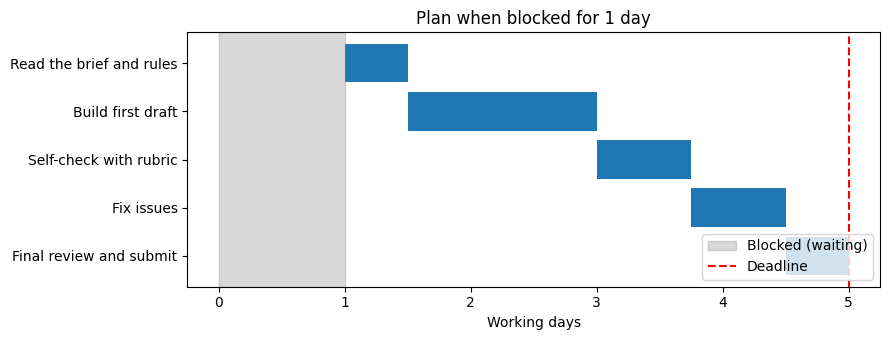


EARLY MESSAGE TO THE TEAM:
  Hi team, quick heads-up. I am blocked on the dataset access since day 1.
  I can still deliver by day 5 if I work 4.0 h/day, but the buffer is gone.
  Options: (1) you unblock me today, (2) we reduce the scope, (3) we move the deadline by 1 day.
  Please tell me which one you prefer.


In [ ]:

# Cell 5: Break work into small tasks, set daily targets, add buffer, warn early when blocked

tasks = [("Read the brief and rules", 2), ("Build first draft", 6), ("Self-check with rubric", 3),
         ("Fix issues", 3), ("Final review and submit", 2)]       # hours (example values)
HPD = 4          # working hours per day
DEADLINE = 5     # deadline in working days
BUFFER = 0.20    # 20% extra time for surprises

def build_plan(tasks, hpd, blocked_days=0, buffer=0.0):
    cursor = blocked_days * hpd
    rows = []
    for name, h in tasks:
        hh = h * (1 + buffer)
        start, end = cursor, cursor + hh
        rows.append({"task": name, "hours": round(hh, 1), "start_x": start / hpd, "width": hh / hpd})
        cursor = end
    finish_day = int((cursor - 1e-9) // hpd) + 1
    return pd.DataFrame(rows), finish_day

def status_for(blocked_days):
    _, fin_plain = build_plan(tasks, HPD, blocked_days, 0.0)
    _, fin_buf = build_plan(tasks, HPD, blocked_days, BUFFER)
    if fin_buf <= DEADLINE:
        s = "ON TRACK"
    elif fin_plain <= DEADLINE:
        s = "TIGHT: no buffer left, tell the team now"
    else:
        s = "LATE RISK: tell the team now"
    total = sum(h for _, h in tasks)
    left_days = DEADLINE - blocked_days
    need = round(total / left_days, 1) if left_days > 0 else float("inf")
    return {"finish_day_no_buffer": fin_plain, "finish_day_with_buffer": fin_buf,
            "hours_per_day_needed": need, "status": s}

plan_table = pd.DataFrame({f"Blocked {b} day(s)": status_for(b) for b in [0, 1, 2]}).T
print(f"Total work: {sum(h for _, h in tasks)} h | Capacity: {HPD} h/day | Deadline: day {DEADLINE} | Buffer: {int(BUFFER*100)}%\n")
print(plan_table.to_string())

# ---- Daily targets for the normal plan ----
def daily_targets(df, hpd):
    out = []
    n_days = math.ceil((df.start_x + df.width).max() - 1e-9)
    for d in range(1, n_days + 1):
        lo, hi = (d - 1) * hpd, d * hpd
        parts = []
        for _, r in df.iterrows():
            s = r.start_x * hpd; e = s + r.width * hpd
            ov = min(hi, e) - max(lo, s)
            if ov > 1e-9:
                parts.append(f"{r.task} ({ov:.1f}h)")
        out.append((d, parts if parts else ["waiting (blocked)"]))
    return out

normal_plan, _ = build_plan(tasks, HPD, 0, BUFFER)
print("\nDAILY TARGETS (normal plan, with buffer):")
for d, parts in daily_targets(normal_plan, HPD):
    print(f"  Day {d}: " + "; ".join(parts))

# ---- Gantt chart: what happens if I am blocked for 1 day ----
blocked_plan, _ = build_plan(tasks, HPD, 1, 0.0)
fig, ax = plt.subplots(figsize=(9, 3.5))
for i, r in blocked_plan.iterrows():
    ax.barh(i, r.width, left=r.start_x, color="tab:blue")
ax.axvspan(0, 1, color="grey", alpha=0.3, label="Blocked (waiting)")
ax.axvline(DEADLINE, color="red", ls="--", label="Deadline")
ax.set_yticks(range(len(blocked_plan))); ax.set_yticklabels(blocked_plan.task); ax.invert_yaxis()
ax.set_xlabel("Working days"); ax.set_title("Plan when blocked for 1 day"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# ---- The early message (do not wait until the last day) ----
print("\nEARLY MESSAGE TO THE TEAM:")
print("  Hi team, quick heads-up. I am blocked on the dataset access since day 1.")
print(f"  I can still deliver by day {DEADLINE} if I work {status_for(1)['hours_per_day_needed']} h/day, but the buffer is gone.")
print("  Options: (1) you unblock me today, (2) we reduce the scope, (3) we move the deadline by 1 day.")
print("  Please tell me which one you prefer.")

Cell 6 (Code): Q4, disagreement settled by evidence

                                      called  precision  recall     f1  recall_small_effects
Expert C: TPM t-test, raw p<0.05       196.0      0.765   0.750  0.758                 0.515
Me: batch + FDR + |log2FC|>1            99.0      1.000   0.495  0.662                 0.165
Expert B: batch + FDR + |log2FC|>0.5   118.0      0.941   0.555  0.698                 0.247

----------------------------------------------------------------
DISAGREEMENT 1: Expert C says TPM + t-test is fine
----------------------------------------------------------------
1. Check facts : we both ran the same data. I wrote down both methods and settings.
2. Evidence    : my F1 = 0.662 | other expert F1 = 0.758
3. Reply       : 'You are right on this point. Your method scored higher on the same data.
                 I will update my approach. Thanks for pushing on it.'

----------------------------------------------------------------
DISAGREEMENT 2: Expert B says a cutoff of 0.5 is better than 1
--------------

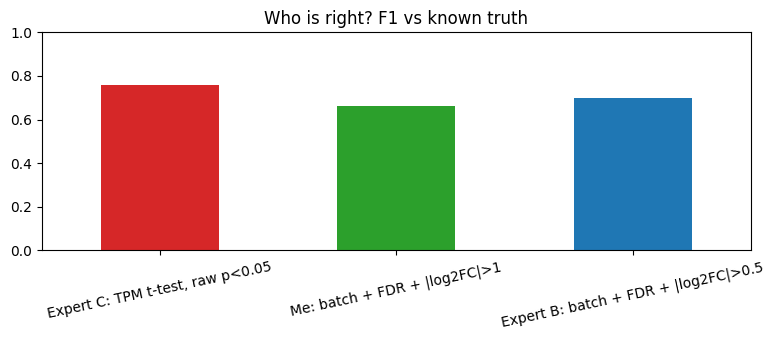

In [ ]:

# Cell 6: Two disagreements, settled with data that has a known truth

counts2, meta2, truth2, lfc2 = make_data(seed=11, n_genes=1500, lfc_values=(-1.5, -0.8, 0.8, 1.5),
                                         n_de=200, batch_sd=0.5)
truth_set = set(truth2.index[truth2])
small_set = set(lfc2.index[np.isclose(lfc2.abs().values, 0.8)])     # genes with a small true effect

c2 = counts2[(counts2 >= 10).sum(axis=1) >= 3]
l2 = np.log2(c2 / c2.sum() * 1e6 + 1)
de2 = de_linear(l2, meta2, use_batch=True)
de2["FDR"] = bh_fdr(de2["pval"].values)

def evaluate(called):
    called = set(called)
    tp = len(called & truth_set)
    prec = tp / max(len(called), 1)
    rec = tp / len(truth_set)
    f1 = 2 * prec * rec / max(prec + rec, 1e-9)
    small_rec = len(called & small_set) / max(len(small_set), 1)
    return {"called": len(called), "precision": round(prec, 3), "recall": round(rec, 3),
            "f1": round(f1, 3), "recall_small_effects": round(small_rec, 3)}

# Expert C: "TPM + t-test with raw p < 0.05 is fine"
scaled = counts2 / counts2.sum() * 1e6
is_h = (meta2.condition == "Healthy").values
_, p_tpm = stats.ttest_ind(scaled.values[:, ~is_h], scaled.values[:, is_h], axis=1)
p_tpm = np.nan_to_num(p_tpm, nan=1.0)

methods = {
    "Expert C: TPM t-test, raw p<0.05": counts2.index[p_tpm < 0.05],
    "Me: batch + FDR + |log2FC|>1": de2.index[(de2.FDR < 0.05) & (de2.log2FC.abs() > 1)],
    "Expert B: batch + FDR + |log2FC|>0.5": de2.index[(de2.FDR < 0.05) & (de2.log2FC.abs() > 0.5)],
}
eval_table = pd.DataFrame({k: evaluate(v) for k, v in methods.items()}).T
print(eval_table.to_string())

def settle(title, other, me="Me: batch + FDR + |log2FC|>1"):
    f_me, f_ot = eval_table.loc[me, "f1"], eval_table.loc[other, "f1"]
    print("\n" + "-" * 64)
    print(title)
    print("-" * 64)
    print("1. Check facts : we both ran the same data. I wrote down both methods and settings.")
    print(f"2. Evidence    : my F1 = {f_me} | other expert F1 = {f_ot}")
    if f_me > f_ot:
        print("3. Reply       : 'I tested both on data with a known answer. My method scored higher. Here is the table.")
        print("                 I may be missing something, so please check my code or share a case where yours works better.'")
        return "I was right on this point (kept my method)"
    else:
        print("3. Reply       : 'You are right on this point. Your method scored higher on the same data.")
        print("                 I will update my approach. Thanks for pushing on it.'")
        return "I was wrong on this point (updated my method)"

outcome1 = settle("DISAGREEMENT 1: Expert C says TPM + t-test is fine", "Expert C: TPM t-test, raw p<0.05")
outcome2 = settle("DISAGREEMENT 2: Expert B says a cutoff of 0.5 is better than 1", "Expert B: batch + FDR + |log2FC|>0.5")

print("\nSmall-effect genes found (recall):",
      {k: v for k, v in eval_table["recall_small_effects"].items()})
print("Lesson: a strict cutoff can miss real but small effects. Evidence, not ego, decides.")

eval_table["f1"].astype(float).plot(kind="bar", figsize=(8, 3.5), ylim=(0, 1), rot=12,
                                    color=["tab:red", "tab:green", "tab:blue"])
plt.title("Who is right? F1 vs known truth"); plt.tight_layout(); plt.show()

Cell 7 (Code): Final scorecard and your honest answer card

In [ ]:

# Cell 7: Scorecard + your behavioral answer card. Fill with REAL facts only.

print("=" * 66)
print("FINAL SCORECARD (interview answer -> proof from this lab)")
print("=" * 66)
print(f"1. Serious error found   -> PCA showed a false signal: {n_naive} false genes, fixed to {n_adj} with batch in the model")
print(f"   Story checklist       -> demo story passed {demo_pass}/{demo_total}; my real story passed {real_pass}/{real_total} (fill Cell 3)")
print(f"2. Explain simply        -> best explanation: {best_explain} (score {explain_table['score'].astype(float).max():.0f}/100)")
print(f"3. Deadlines             -> 0 blocked days: {plan_table.iloc[0]['status']}")
print(f"                            1 blocked day : {plan_table.iloc[1]['status']}")
print(f"                            2 blocked days: {plan_table.iloc[2]['status']}")
print(f"4. Disagreement          -> vs Expert C: {outcome1}")
print(f"                            vs Expert B: {outcome2}")

# ---------- YOUR BEHAVIORAL ANSWER CARD ----------
my_card = {
    "error_story_project": FILL,      # real project where you found an error
    "error_story_number": FILL,       # one real number, for example "genes dropped from 412 to 37"
    "deadline_example": FILL,         # real example: what you delivered, and by when
    "when_I_was_blocked": FILL,       # what you did and who you told
    "disagreement_example": FILL,     # real example, and how it ended
    "what_I_learned": FILL,           # one honest lesson
}
print("\nMY BEHAVIORAL ANSWER CARD")
for k, v in my_card.items():
    print(f"  {k:>22}: {v}")
missing = [k for k, v in my_card.items() if v == FILL]
print("  STATUS:", "Ready to use" if not missing else "Fill these first: " + ", ".join(missing))

print("\nEnvironment: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| seed", SEED)
print("Note: the DE model is a simple linear model for speed. Use DESeq2/edgeR on real counts.")

FINAL SCORECARD (interview answer -> proof from this lab)
1. Serious error found   -> PCA showed a false signal: 0 false genes, fixed to 0 with batch in the model
   Story checklist       -> demo story passed 6/6; my real story passed 1/6 (fill Cell 3)
2. Explain simply        -> best explanation: C. Simple (score 86/100)
3. Deadlines             -> 0 blocked days: ON TRACK
                            1 blocked day : TIGHT: no buffer left, tell the team now
                            2 blocked days: LATE RISK: tell the team now
4. Disagreement          -> vs Expert C: I was wrong on this point (updated my method)
                            vs Expert B: I was wrong on this point (updated my method)

MY BEHAVIORAL ANSWER CARD
     error_story_project: FILL_ME
      error_story_number: FILL_ME
        deadline_example: FILL_ME
      when_I_was_blocked: FILL_ME
    disagreement_example: FILL_ME
          what_I_learned: FILL_ME
  STATUS: Fill these first: error_story_project, error_story

File name changes

In [ ]:

%%bash
set -e

OLD="gig3-ai-ml-genomics-precision-medicine"
NEW_NAME="gig3-ai-ml-genomics-precision-medicine-several-projects"

git clone https://github.com/bejon23/AI-Data-Eng-Architect-Bio-Health-Operational-.git
cd AI-Data-Eng-Architect-Bio-Health-Operational-

git mv "$OLD" "$NEW_NAME"
git config user.email "bejon23@gmail.com"
git config user.name "bejon23"
git commit -m "Rename gig3 folder"
git status

[main 01f94c4] Rename gig3 folder
 12 files changed, 0 insertions(+), 0 deletions(-)
 rename {gig3-ai-ml-genomics-precision-medicine => gig3-ai-ml-genomics-precision-medicine-several-projects}/README.md (100%)
 rename {gig3-ai-ml-genomics-precision-medicine => gig3-ai-ml-genomics-precision-medicine-several-projects}/gig3 Project 6: Biology AI Benchmark Builder and Answer Judge (100%)
 rename {gig3-ai-ml-genomics-precision-medicine => gig3-ai-ml-genomics-precision-medicine-several-projects}/project1-alphafold2-esm2-brca-variant-effect/README.md (100%)
 rename {gig3-ai-ml-genomics-precision-medicine => gig3-ai-ml-genomics-precision-medicine-several-projects}/project1-alphafold2-esm2-brca-variant-effect/requirements.txt (100%)
 rename {gig3-ai-ml-genomics-precision-medicine => gig3-ai-ml-genomics-precision-medicine-several-projects}/project2-multiomics-cancer-subtype-discovery/README.md (100%)
 rename {gig3-ai-ml-genomics-precision-medicine => gig3-ai-ml-genomics-precision-medicine-severa

Cloning into 'AI-Data-Eng-Architect-Bio-Health-Operational-'...
